# NASA Turbofan Motorları — Kalan Faydalı Ömür (RUL) Tahmini — FD003

Bu çalışmada NASA'nın **C-MAPSS** veri setini kullanarak uçak motorlarının **kalan faydalı ömrünü (RUL — Remaining Useful Life)** tahmin edeceğiz.

Her motor ilk başta sağlıklı çalışıyor, zamanla bir arıza gelişiyor ve sonunda bozuluyor. Amacımız: motorun sensör ölçümlerine bakarak **"bu motor bozulmadan önce daha kaç çevrim (uçuş) çalışabilir?"** sorusunu cevaplamak.

**FD003 veri setinin özellikleri:**
- Eğitim (train) motor sayısı: **100**
- Test motor sayısı: **100**
- Çalışma koşulu sayısı: **1 (deniz seviyesi)**
- Arıza tipi sayısı: **2 (HPC bozulması ve Fan bozulması)**

Colab'ın sol tarafındaki **📁 Dosyalar** paneline şu 3 dosyayı sürükleyip bırakın:
- `train_FD003.txt`
- `test_FD003.txt`
- `RUL_FD003.txt`

Aşağıdaki hücreyi çalıştırarak kullanacağımız kütüphaneleri yükleyin.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score

## 1. TXT dosyalarını CSV'ye çevirme

Dosyalarımız `.txt` formatında: sütunlar **boşlukla** ayrılmış ve **sütun başlığı yok**. Önce bunları düzgün sütun adlarına sahip birer tabloya (DataFrame) çevirip **CSV** (virgülle ayrılmış değerler) olarak kaydedeceğiz.

`readme.txt` dosyasına göre 26 sütun var: motor numarası, çevrim, 3 çalışma ayarı ve 21 sensör. Aşağıdaki hücreyi çalıştırarak sütun adlarını tanımlayın.

In [2]:
column_names = ["unit", "cycle", "setting_1", "setting_2", "setting_3",
                "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
                "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
                "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
                "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
                "sensor_21"]

`train_FD003.txt` dosyasını `df_train` adlı bir DataFrame'e yükleyin.

<details>
    <summary> İpucu 💡 </summary>

`pd.read_csv()` fonksiyonunu üç ek argümanla kullanabilirsiniz:
- `sep=r"\s+"` → sütunlar bir veya daha fazla boşlukla ayrılmış
- `header=None` → dosyada başlık satırı yok
- `names=column_names` → sütun adlarını biz veriyoruz

</details>

In [3]:
df_train = pd.read_csv("train_FD003.txt", sep=r"\s+", header=None, names=column_names)
df_train.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0005,0.0004,100.0,518.67,642.36,1583.23,1396.84,14.62,21.61,553.97,2387.96,9062.17,1.3,47.30,522.31,2388.01,8145.32,8.4246,0.03,391,2388,100.0,39.11,23.3537
1,1,2,0.0008,-0.0003,100.0,518.67,642.50,1584.69,1396.89,14.62,21.61,554.55,2388.00,9061.78,1.3,47.23,522.42,2388.03,8152.85,8.4403,0.03,392,2388,100.0,38.99,23.4491
2,1,3,-0.0014,-0.0002,100.0,518.67,642.18,1582.35,1405.61,14.62,21.61,554.43,2388.03,9070.23,1.3,47.22,522.03,2388.00,8150.17,8.3901,0.03,391,2388,100.0,38.85,23.3669
3,1,4,-0.0020,0.0001,100.0,518.67,642.92,1585.61,1392.27,14.62,21.61,555.21,2388.00,9064.57,1.3,47.24,522.49,2388.08,8146.56,8.3878,0.03,392,2388,100.0,38.96,23.2951
4,1,5,0.0016,0.0000,100.0,518.67,641.68,1588.63,1397.65,14.62,21.61,554.74,2388.04,9076.14,1.3,47.15,522.58,2388.03,8147.80,8.3869,0.03,392,2388,100.0,39.14,23.4583


Aynı şekilde `test_FD003.txt` dosyasını `df_test` içine yükleyin.

`RUL_FD003.txt` dosyasında ise tek bir sütun var. Onu `df_rul` içine, sütun adı `"RUL"` olacak şekilde yükleyin.

In [4]:
df_test = pd.read_csv("test_FD003.txt", sep=r"\s+", header=None, names=column_names)
df_rul = pd.read_csv("RUL_FD003.txt", sep=r"\s+", header=None, names=["RUL"])
df_rul.head()

,RUL
0,44
1,51
2,27
3,120
4,101


Üç tabloyu da `.to_csv()` ile CSV olarak kaydedin. Satır numaralarının dosyaya yazılmaması için `index=False` kullanın.

In [5]:
df_train.to_csv("train_FD003.csv", index=False)
df_test.to_csv("test_FD003.csv", index=False)
df_rul.to_csv("RUL_FD003.csv", index=False)

Bundan sonra CSV dosyalarıyla çalışacağız. Üç CSV dosyasını tekrar `df_train`, `df_test` ve `df_rul` içine okuyun.

In [6]:
df_train = pd.read_csv("train_FD003.csv")
df_test = pd.read_csv("test_FD003.csv")
df_rul = pd.read_csv("RUL_FD003.csv")

## 2. Keşif (Exploratory Analysis)

`df_train` tablosunun ilk 5 satırına bakın.

In [7]:
df_train.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0005,0.0004,100.0,518.67,642.36,1583.23,1396.84,14.62,21.61,553.97,2387.96,9062.17,1.3,47.30,522.31,2388.01,8145.32,8.4246,0.03,391,2388,100.0,39.11,23.3537
1,1,2,0.0008,-0.0003,100.0,518.67,642.50,1584.69,1396.89,14.62,21.61,554.55,2388.00,9061.78,1.3,47.23,522.42,2388.03,8152.85,8.4403,0.03,392,2388,100.0,38.99,23.4491
2,1,3,-0.0014,-0.0002,100.0,518.67,642.18,1582.35,1405.61,14.62,21.61,554.43,2388.03,9070.23,1.3,47.22,522.03,2388.00,8150.17,8.3901,0.03,391,2388,100.0,38.85,23.3669
3,1,4,-0.0020,0.0001,100.0,518.67,642.92,1585.61,1392.27,14.62,21.61,555.21,2388.00,9064.57,1.3,47.24,522.49,2388.08,8146.56,8.3878,0.03,392,2388,100.0,38.96,23.2951
4,1,5,0.0016,0.0000,100.0,518.67,641.68,1588.63,1397.65,14.62,21.61,554.74,2388.04,9076.14,1.3,47.15,522.58,2388.03,8147.80,8.3869,0.03,392,2388,100.0,39.14,23.4583


Bir satır neyi temsil eder? Hangi bilgileri bulabilirsiniz?

> **Örnek cevap:** Her satır, **bir motorun bir çevrimdeki (bir uçuştaki) ölçümüdür**. `unit` motor numarası, `cycle` kaçıncı çevrim olduğu, `setting_1-3` çalışma ayarları, `sensor_1-21` ise o çevrimde ölçülen sensör değerleridir.

### Sensör sözlüğü
Sütunlarda `sensor_1`, `sensor_2`... yazıyor ama bunların **gerçekte ne ölçtüğünü** bilmeden yorum yapmak zor. NASA'nın makalesindeki sensör açıklamalarını bir **sözlük (dictionary)** içine koyduk. Sözlük, bir anahtara (`"sensor_1"`) karşılık bir değer (`"(Fan inlet temperature) (◦R)"`) saklar.

Aşağıdaki hücreyi çalıştırın.

In [8]:
Sensor_dictionary = {}
dict_list = ["(Fan inlet temperature) (◦R)",
             "(LPC outlet temperature) (◦R)",
             "(HPC outlet temperature) (◦R)",
             "(LPT outlet temperature) (◦R)",
             "(Fan inlet Pressure) (psia)",
             "(bypass-duct pressure) (psia)",
             "(HPC outlet pressure) (psia)",
             "(Physical fan speed) (rpm)",
             "(Physical core speed) (rpm)",
             "(Engine pressure ratio(P50/P2)",
             "(HPC outlet Static pressure) (psia)",
             "(Ratio of fuel flow to Ps30) (pps/psia)",
             "(Corrected fan speed) (rpm)",
             "(Corrected core speed) (rpm)",
             "(Bypass Ratio) ",
             "(Burner fuel-air ratio)",
             "(Bleed Enthalpy)",
             "(Required fan speed)",
             "(Required fan conversion speed)",
             "(High-pressure turbines Cool air flow)",
             "(Low-pressure turbines Cool air flow)"]

i = 1
for x in dict_list:
    Sensor_dictionary["sensor_" + str(i)] = x
    i += 1

pd.Series(Sensor_dictionary, name="Ne ölçüyor?").to_frame()

,Ne ölçüyor?
sensor_1,(Fan inlet temperature) (◦R)
sensor_2,(LPC outlet temperature) (◦R)
sensor_3,(HPC outlet temperature) (◦R)
sensor_4,(LPT outlet temperature) (◦R)
sensor_5,(Fan inlet Pressure) (psia)
sensor_6,(bypass-duct pressure) (psia)
sensor_7,(HPC outlet pressure) (psia)
sensor_8,(Physical fan speed) (rpm)
sensor_9,(Physical core speed) (rpm)
sensor_10,(Engine pressure ratio(P50/P2)


Kısaltmalar: **Fan** = ön pervane, **LPC / HPC** = alçak / yüksek basınçlı kompresör, **LPT** = alçak basınçlı türbin, **◦R** = Rankine (sıcaklık birimi), **psia** = basınç birimi, **rpm** = dakikadaki devir. Yani sensörler motorun farklı bölümlerindeki **sıcaklık, basınç ve devir** değerlerini ölçüyor.

Tabloların kaç satır ve kaç sütundan oluştuğuna bakın. Train ve test verisinde kaç farklı motor var?

<details>
    <summary> İpucu 💡 </summary>

`.shape` satır ve sütun sayısını verir. `.nunique()` bir sütundaki farklı değerlerin sayısını verir.

</details>

In [9]:
print("Train boyutu:", df_train.shape)
print("Test boyutu:", df_test.shape)
print("Train motor sayısı:", df_train["unit"].nunique())
print("Test motor sayısı:", df_test["unit"].nunique())

Train boyutu: (24720, 26)
Test boyutu: (16596, 26)
Train motor sayısı: 100
Test motor sayısı: 100


`.describe()` ile sayısal sütunların özet istatistiklerine bakın.

In [10]:
df_train.describe()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
count,24720.000000,24720.000000,24720.000000,24720.000000,24720.0,24720.00,24720.000000,24720.000000,24720.000000,2.472000e+04,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,24720.000000,2.472000e+04,24720.000000,24720.0,24720.0,24720.000000,24720.000000
mean,48.631877,139.077063,-0.000024,0.000005,100.0,518.67,642.457858,1588.079175,1404.471212,1.462000e+01,21.595841,555.143808,2388.071555,9064.110809,1.301232,47.415707,523.050873,2388.071643,8144.202916,8.396176,3.000000e-02,392.566545,2388.0,100.0,38.988552,23.393024
std,29.348985,98.846675,0.002194,0.000294,0.0,0.00,0.523031,6.810418,9.773178,3.552786e-15,0.018116,3.437343,0.158285,19.980294,0.003485,0.300074,3.255314,0.158121,16.504118,0.060512,6.939034e-18,1.761459,0.0,0.0,0.248865,0.149234
min,1.000000,1.000000,-0.008600,-0.000600,100.0,518.67,640.840000,1564.300000,1377.060000,1.462000e+01,21.450000,549.610000,2386.900000,9017.980000,1.290000,46.690000,517.770000,2386.930000,8099.680000,8.156300,3.000000e-02,388.000000,2388.0,100.0,38.170000,22.872600
25%,23.000000,62.000000,-0.001500,-0.000200,100.0,518.67,642.080000,1583.280000,1397.187500,1.462000e+01,21.580000,553.110000,2388.000000,9051.920000,1.300000,47.190000,521.150000,2388.010000,8134.510000,8.360600,3.000000e-02,391.000000,2388.0,100.0,38.830000,23.296200
50%,47.000000,124.000000,-0.000000,-0.000000,100.0,518.67,642.400000,1587.520000,1402.910000,1.462000e+01,21.600000,554.050000,2388.070000,9060.010000,1.300000,47.360000,521.980000,2388.070000,8141.200000,8.398300,3.000000e-02,392.000000,2388.0,100.0,38.990000,23.391600
75%,74.000000,191.000000,0.001500,0.000300,100.0,518.67,642.790000,1592.412500,1410.600000,1.462000e+01,21.610000,556.040000,2388.140000,9070.092500,1.300000,47.600000,523.840000,2388.140000,8149.230000,8.437000,3.000000e-02,394.000000,2388.0,100.0,39.140000,23.483300
max,100.000000,525.000000,0.008600,0.000700,100.0,518.67,645.110000,1615.390000,1441.160000,1.462000e+01,21.610000,570.490000,2388.600000,9234.350000,1.320000,48.440000,537.400000,2388.610000,8290.550000,8.570500,3.000000e-02,399.000000,2388.0,100.0,39.850000,23.950500


`describe()` bize her sütun için şunları verir:
- `count`: dolu değer sayısı
- `mean`: ortalama
- `std`: standart sapma → değerler ortalamadan ne kadar uzaklaşıyor? **0'a yakınsa sütun neredeyse hiç değişmiyor demektir.**
- `min` / `max`: en küçük / en büyük değer
- `25%`, `50%`, `75%`: çeyrekler (`50%` = medyan)

Hangi sütunların `std` değeri 0 veya 0'a çok yakın? Bu sütunlar model için faydalı olur mu?

> **Örnek cevap:** Std değeri 0'a çok yakın (0.01'den küçük) olan sütunlar: `setting_1`, `setting_2`, `setting_3`, `sensor_1`, `sensor_5`, `sensor_10`, `sensor_16`, `sensor_18`, `sensor_19`. Bu sütunlar motor sağlıklıyken de bozulmaya yakınken de neredeyse aynı değeri gösteriyor. Değişmeyen bir değer bize motorun ömrü hakkında **hiçbir bilgi vermez**, bu yüzden modelden çıkarabiliriz.

Tabloda boş (`NaN`) değer var mı? Her sütun için kontrol edin.

<details>
    <summary> İpucu 💡 </summary>

`.isnull()` her hücre için boş mu değil mi (True/False) döndürür. Arkasına `.sum()` eklerseniz her sütundaki boş değer sayısını verir.

</details>

In [11]:
df_train.isnull().sum()

unit         0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

Değeri tam olarak **0** olan hücreleri sayın. Hangi sütunlarda 0 değeri var?

In [12]:
(df_train == 0).sum()

unit            0
cycle           0
setting_1     413
setting_2    2451
setting_3       0
sensor_1        0
sensor_2        0
sensor_3        0
sensor_4        0
sensor_5        0
sensor_6        0
sensor_7        0
sensor_8        0
sensor_9        0
sensor_10       0
sensor_11       0
sensor_12       0
sensor_13       0
sensor_14       0
sensor_15       0
sensor_16       0
sensor_17       0
sensor_18       0
sensor_19       0
sensor_20       0
sensor_21       0
dtype: int64

Boş ve sıfır değer kontrolünün sonucu nedir? Sıfır değerleri bir sorun mu?

> **Örnek cevap:** Veride hiç boş değer yok. Sıfır değerleri yalnızca `setting_1` ve `setting_2` sütunlarında görülüyor. Bu sütunlar 0 etrafında çok küçük değerler alan ayarlar; sıfır burada **gerçek bir ölçüm**, hata değil. Sensörlerde sıfır yok. Yani temizlememiz gereken bir şey yok.

Şimdi **medyan** ve **mod** değerlerine bakalım:
- **Medyan:** Değerleri küçükten büyüğe sıraladığımızda tam ortada kalan değer. Uç değerlerden (çok büyük/küçük değerlerden) etkilenmez.
- **Mod:** En sık tekrar eden değer.

`sensor_11` sütununun ortalamasını (`mean`), medyanını (`median`) ve modunu (`mode`) hesaplayın.

In [13]:
print("Ortalama:", df_train["sensor_11"].mean())
print("Medyan:", df_train["sensor_11"].median())
print("Mod:", df_train["sensor_11"].mode()[0])

Ortalama: 47.415706715210355
Medyan: 47.36
Mod: 47.19


Ortalama ile medyan birbirine yakın mı? Bu bize ne söyler?

> **Örnek cevap:** Ortalama ile medyan birbirine çok yakın. Bu, `sensor_11` değerlerinde ortalamayı bir tarafa çeken aşırı uç değerlerin olmadığını, dağılımın dengeli olduğunu gösterir. Eğer ikisi arasında büyük fark olsaydı, uç değerler var demek olurdu.

`sensor_1` sütununda her değerin kaç kez tekrar ettiğini sayın. Mod (en sık görülen değer) kaç kez tekrar ediyor?

<details>
    <summary> İpucu 💡 </summary>

`.value_counts()` her değerin kaç kez tekrar ettiğini sayar.

</details>

In [14]:
df_train["sensor_1"].value_counts()

sensor_1
518.67    24720
Name: count, dtype: int64

> **Örnek cevap:** `sensor_1` tüm satırlarda **aynı değeri** alıyor (mod = tüm değerler). Hiç değişmeyen bir sensör motorun durumu hakkında bilgi vermez. Bu, `describe()` ile bulduğumuz std ≈ 0 sonucunu doğruluyor.

Her motorun arızalanana kadar kaç çevrim çalıştığını hesaplayın. Sonra bu değerlerin özet istatistiğine bakın.

<details>
    <summary> İpucu 💡 </summary>

Her motor için en büyük `cycle` değeri, o motorun ömrüdür: `groupby("unit")["cycle"].max()`

</details>

In [15]:
engine_life = df_train.groupby("unit")["cycle"].max()
engine_life.describe()

count    100.00000
mean     247.20000
std       86.48384
min      145.00000
25%      189.75000
50%      220.50000
75%      279.75000
max      525.00000
Name: cycle, dtype: float64

Motor ömürlerinin dağılımını bir histogram ile çizin.

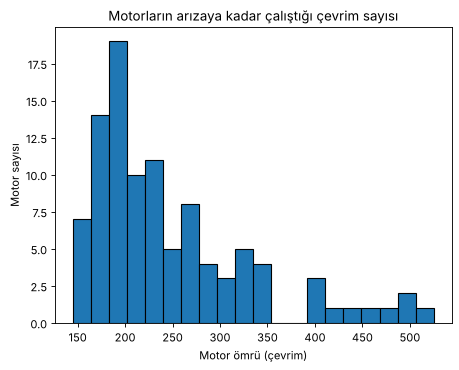

In [16]:
engine_life.plot(kind="hist", bins=20, edgecolor="black")
plt.xlabel("Motor ömrü (çevrim)")
plt.ylabel("Motor sayısı")
plt.title("Motorların arızaya kadar çalıştığı çevrim sayısı")
plt.show()

En kısa ve en uzun ömürlü motor kaç çevrim çalışmış? Bütün motorlar aynı sürede mi bozuluyor?

> **Örnek cevap:** En kısa ömürlü motor 145, en uzun ömürlü motor 525 çevrim çalışmış; ortalama yaklaşık 247.2 çevrim. Motorlar çok farklı sürelerde bozuluyor. Bu yüzden "her motor X çevrimde bozulur" diyemeyiz; sensörlere bakarak tahmin yapmamız gerekiyor.

Aşağıdaki kodu çalıştırarak **1 numaralı motorun** `sensor_11` değerinin zaman içinde nasıl değiştiğini görün.

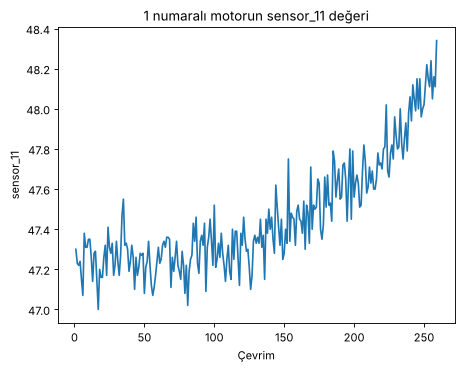

In [17]:
engine_1 = df_train[df_train["unit"] == 1]

plt.plot(engine_1["cycle"], engine_1["sensor_11"])
plt.xlabel("Çevrim")
plt.ylabel("sensor_11")
plt.title("1 numaralı motorun sensor_11 değeri")
plt.show()

Grafikte ne görüyorsunuz?

> **Örnek cevap:** Motor ilk çevrimlerde sabit bir seviyede çalışıyor, ömrünün sonuna doğru `sensor_11` değeri belirgin şekilde **artıyor**. Yani sensör değerleri motorun yıpranmasını yansıtıyor; modelimiz bu değişimi öğrenerek tahmin yapacak.

## 3. Temizlik: Bilgi vermeyen sütunları çıkarma

Std değeri 0.01'den küçük olan sütunları bulun ve listesini `constant_cols` değişkenine kaydedin.

<details>
    <summary> İpucu 💡 </summary>

```python
stds = df_train.std()
constant_cols = stds[stds < 0.01].index
```
İlk satır her sütunun std'sini hesaplar, ikinci satır std'si 0.01'den küçük olanların adlarını seçer.

</details>

In [18]:
stds = df_train.std()
constant_cols = stds[stds < 0.01].index
print(constant_cols)

Index(['setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_5',
       'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19'],
      dtype='str')


Sözlükten bakarak bu sütunların ne ölçtüğünü görün. (`.get()`, sözlükte karşılığı olmayan anahtarlar için "çalışma ayarı" yazar; `setting` sütunları sensör değildir.)

In [19]:
for c in constant_cols:
    print(c, "→", Sensor_dictionary.get(c, "çalışma ayarı"))

setting_1 → çalışma ayarı
setting_2 → çalışma ayarı
setting_3 → çalışma ayarı
sensor_1 → (Fan inlet temperature) (◦R)
sensor_5 → (Fan inlet Pressure) (psia)
sensor_10 → (Engine pressure ratio(P50/P2)
sensor_16 → (Burner fuel-air ratio)
sensor_18 → (Required fan speed)
sensor_19 → (Required fan conversion speed)


Bu sütunları hem `df_train` hem de `df_test` tablosundan silin. (Modelin test verisinde de aynı sütunları görmesi gerekir!)

In [20]:
df_train = df_train.drop(columns=constant_cols)
df_test = df_test.drop(columns=constant_cols)
df_train.head()

,unit,cycle,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,1,642.36,1583.23,1396.84,21.61,553.97,2387.96,9062.17,47.30,522.31,2388.01,8145.32,8.4246,391,39.11,23.3537
1,1,2,642.50,1584.69,1396.89,21.61,554.55,2388.00,9061.78,47.23,522.42,2388.03,8152.85,8.4403,392,38.99,23.4491
2,1,3,642.18,1582.35,1405.61,21.61,554.43,2388.03,9070.23,47.22,522.03,2388.00,8150.17,8.3901,391,38.85,23.3669
3,1,4,642.92,1585.61,1392.27,21.61,555.21,2388.00,9064.57,47.24,522.49,2388.08,8146.56,8.3878,392,38.96,23.2951
4,1,5,641.68,1588.63,1397.65,21.61,554.74,2388.04,9076.14,47.15,522.58,2388.03,8147.80,8.3869,392,39.14,23.4583


## 4. Hedef değişkeni oluşturma: RUL

Modelimizin tahmin edeceği değer **RUL**: motorun bozulmadan önce **kalan** çevrim sayısı. Train verisinde bu sütun hazır değil, biz hesaplayacağız.

Train verisinde her motor **arızalanana kadar** çalışıyor. Yani bir motorun son çevrimi, arıza anı. Buna göre:

**RUL = motorun son çevrimi − şu anki çevrim**

Örnek: Motor 192 çevrimde bozulduysa, 100. çevrimde RUL = 192 − 100 = 92.

Önce her motorun son çevrimini bulun ve `max_cycles` adlı bir tabloya kaydedin. Sütun adları `unit` ve `max_cycle` olsun.

In [21]:
max_cycles = df_train.groupby("unit")["cycle"].max().reset_index()
max_cycles.columns = ["unit", "max_cycle"]
max_cycles.head()

,unit,max_cycle
0,1,259
1,2,253
2,3,222
3,4,272
4,5,213


`max_cycles` tablosunu `unit` sütunu üzerinden `df_train` ile birleştirin (merge). Ardından `RUL` sütununu hesaplayın ve artık gerekmeyen `max_cycle` sütununu silin.

<details>
    <summary> İpucu 💡 </summary>

```python
df_train = df_train.merge(max_cycles, on="unit")
```
Ardından: `df_train["RUL"] = df_train["max_cycle"] - df_train["cycle"]`

</details>

In [22]:
df_train = df_train.merge(max_cycles, on="unit")
df_train["RUL"] = df_train["max_cycle"] - df_train["cycle"]
df_train = df_train.drop(columns="max_cycle")
df_train[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,1,258
1,1,2,257
2,1,3,256
3,1,4,255
4,1,5,254


Kontrol: 1 numaralı motorun **son 5 satırına** bakın. Son satırda RUL kaç olmalı?

In [23]:
df_train[df_train["unit"] == 1][["unit", "cycle", "RUL"]].tail()

,unit,cycle,RUL
254,1,255,4
255,1,256,3
256,1,257,2
257,1,258,1
258,1,259,0


Her sensörün RUL ile **korelasyonunu** hesaplayın ve küçükten büyüğe sıralayın.

<details>
    <summary> İpucu 💡 </summary>

`df_train.corr()` tüm sütunlar arasındaki korelasyonu verir. Sadece RUL sütununu almak için: `df_train.corr()["RUL"]`

Korelasyon -1 ile +1 arasındadır:
- **+1'e yakın:** sensör arttıkça RUL da artıyor
- **-1'e yakın:** sensör arttıkça RUL azalıyor (motor bozulmaya yaklaşıyor)
- **0'a yakın:** belirgin bir ilişki yok

</details>

In [24]:
df_train.corr()["RUL"].sort_values()

sensor_11   -0.688915
sensor_4    -0.657224
sensor_13   -0.656340
sensor_8    -0.655345
sensor_17   -0.649220
sensor_3    -0.624236
sensor_2    -0.590564
sensor_9    -0.551843
cycle       -0.482744
sensor_14   -0.481807
sensor_12   -0.329452
sensor_7    -0.315048
sensor_6    -0.215352
unit        -0.077196
sensor_15   -0.016501
sensor_21    0.033465
sensor_20    0.037782
RUL          1.000000
Name: RUL, dtype: float64

Aşağıdaki kodu çalıştırarak korelasyonları bir ısı haritası (heatmap) olarak görün.

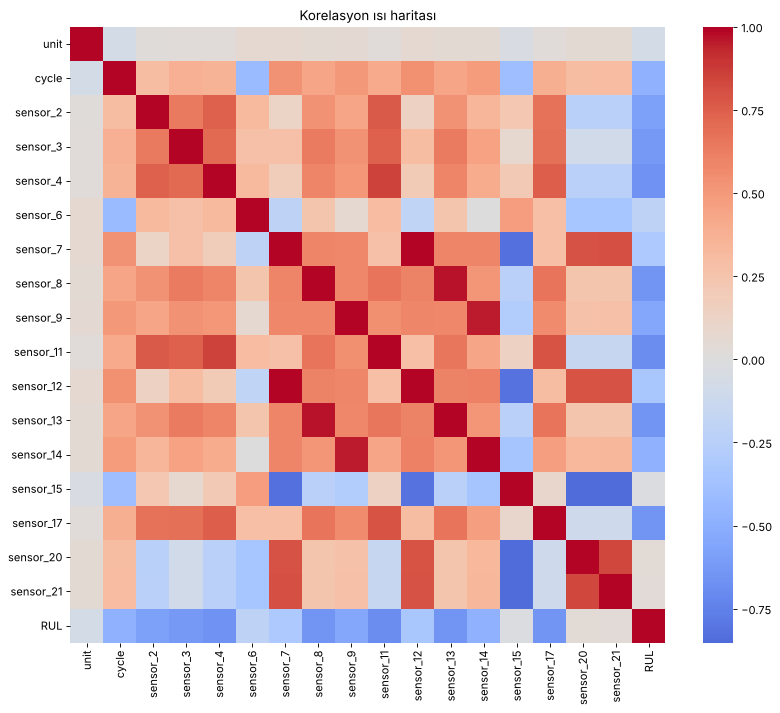

In [25]:
plt.figure(figsize=(12, 10))
sns.heatmap(df_train.corr(), cmap="coolwarm", center=0)
plt.title("Korelasyon ısı haritası")
plt.show()

Aşağıdaki kodu çalıştırarak RUL ile en güçlü ilişkiye sahip 5 sensörü ve **ne ölçtüklerini** görün.

In [26]:
corr = df_train.corr()["RUL"]
corr = corr[corr.index.str.startswith("sensor")]
top5 = corr.abs().sort_values(ascending=False).head(5).index

for s in top5:
    print(s, "| korelasyon:", round(corr[s], 2), "|", Sensor_dictionary[s])

sensor_11 | korelasyon: -0.69 | (HPC outlet Static pressure) (psia)
sensor_4 | korelasyon: -0.66 | (LPT outlet temperature) (◦R)
sensor_13 | korelasyon: -0.66 | (Corrected fan speed) (rpm)
sensor_8 | korelasyon: -0.66 | (Physical fan speed) (rpm)
sensor_17 | korelasyon: -0.65 | (Bleed Enthalpy)


RUL ile en güçlü ilişkiye sahip sensörler hangileri? Sözlüğe bakarak ne ölçtüklerini de yazın.

> **Örnek cevap:** `sensor_11` (HPC çıkış statik basıncı) ve `sensor_4` (LPT çıkış sıcaklığı) başta olmak üzere listedeki sensörler RUL ile belirgin ilişkiye sahip. Negatif korelasyon, motor bozulmaya yaklaştıkça (RUL azaldıkça) sensör değerinin arttığı anlamına gelir. Sözlükten görüldüğü gibi bunlar motorun sıcak ve yüksek basınçlı bölümlerini ölçen sensörler; yıpranma en çok bu bölgelerde belli oluyor.

## 5. Test verisini hazırlama

Test verisi train'den farklı: test motorları **arızadan bir süre önce** kesiliyor. Yani her test motorunun **son satırındaki** durumu biliyoruz ve `RUL_FD003.txt` dosyası bize **o son satırdan sonra** motorun kaç çevrim daha çalıştığını (gerçek RUL'u) söylüyor.

Bu yüzden test verisinde her motorun **sadece son satırını** alacağız. Her motorun son satırını `df_test_last` içine kaydedin.

<details>
    <summary> İpucu 💡 </summary>

`df_test.groupby("unit").last().reset_index()` her motor için son satırı alır.

</details>

In [27]:
df_test_last = df_test.groupby("unit").last().reset_index()
df_test_last.head()

,unit,cycle,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21
0,1,233,642.59,1592.40,1409.87,21.58,560.53,2388.22,9085.50,47.53,528.05,2388.23,8158.77,8.2966,393,39.43,23.5679
1,2,124,642.56,1587.42,1409.69,21.61,553.33,2388.18,9050.97,47.71,520.90,2388.17,8128.04,8.4514,392,38.83,23.2821
2,3,234,642.75,1591.93,1417.66,21.60,563.61,2388.31,9091.69,47.68,531.36,2388.33,8173.56,8.3057,395,39.27,23.6440
3,4,68,642.28,1584.68,1406.56,21.61,552.75,2388.07,9048.23,47.26,521.27,2388.09,8133.78,8.4337,392,38.70,23.3804
4,5,138,642.15,1580.59,1397.26,21.58,553.82,2387.96,9050.89,47.09,521.74,2387.96,8132.51,8.3900,390,38.89,23.4463


`df_rul` tablosundaki gerçek RUL değerlerini `df_test_last` tablosuna `RUL` adlı yeni bir sütun olarak ekleyin. (İki tabloda da motorlar 1'den başlayarak aynı sırada.)

In [28]:
df_test_last["RUL"] = df_rul["RUL"]
df_test_last[["unit", "cycle", "RUL"]].head()

,unit,cycle,RUL
0,1,233,44
1,2,124,51
2,3,234,27
3,4,68,120
4,5,138,101


Son olarak modelde kullanacağımız **özellikleri (features)** belirleyelim: `unit`, `cycle` ve `RUL` dışındaki tüm sütunlar.

> `unit` sadece bir motor numarası, motorun sağlığı hakkında bilgi vermez. `cycle` testte motorun ömrünün ortasında da kesilebilir, yanıltıcı olur. `RUL` ise tahmin etmek istediğimiz şeyin kendisi!

In [29]:
features = df_train.columns.drop(["unit", "cycle", "RUL"])
print(features)

Index(['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8',
       'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14',
       'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21'],
      dtype='str')


### Özellikleri ölçekleme: MinMaxScaler

Sensörlerin değer aralıkları çok farklı: biri 8-9 civarında, diğeri 9000 civarında. **MinMaxScaler** her sütunu **0 ile 1 arasına** sıkıştırır:

**yeni değer = (değer − sütunun min'i) / (sütunun max'ı − min'i)**

En küçük değer 0, en büyük değer 1 olur. Lojistik Regresyon, SVR ve KNN gibi modeller büyük sayılı sütunu gereğinden fazla önemser, ölçekleme bunu eşitler. (Düz Lineer Regresyonun tahminleri ölçeklemeden etkilenmez; ölçekleme yalnızca katsayıları karşılaştırmayı kolaylaştırır.) **Random Forest'in ölçeklemeye ihtiyacı yoktur** (ağaçlar değerleri büyüklüğe göre değil eşiklere göre böler), bu yüzden aşağıdaki ölçekli veriyi bu çalışmadaki modellerde kullanmayacağız; amaç ölçeklemenin ne yaptığını görmek.

> **Önemli:** `fit_transform` sadece **train** verisinde kullanılır (min ve max train'den öğrenilir). Test verisine aynı kural `transform` ile uygulanır. Test verisinde `fit_transform` kullanmak, test verisinden bilgi sızdırmak demektir.

Aşağıdaki kodu çalıştırın.

In [30]:
minmax_scaler = MinMaxScaler()
X_train_s = pd.DataFrame(minmax_scaler.fit_transform(df_train[features]), columns=features)
X_test_s = pd.DataFrame(minmax_scaler.transform(df_test_last[features]), columns=features)

print("Train min:", round(X_train_s.min().min(), 2), "| Train max:", round(X_train_s.max().max(), 2))

Train min: 0.0 | Train max: 1.0


Ölçeklenmiş train verisinin her özelliği için histogram çizin. Dağılımların şekli değişmez, sadece değer aralığı 0-1 olur.

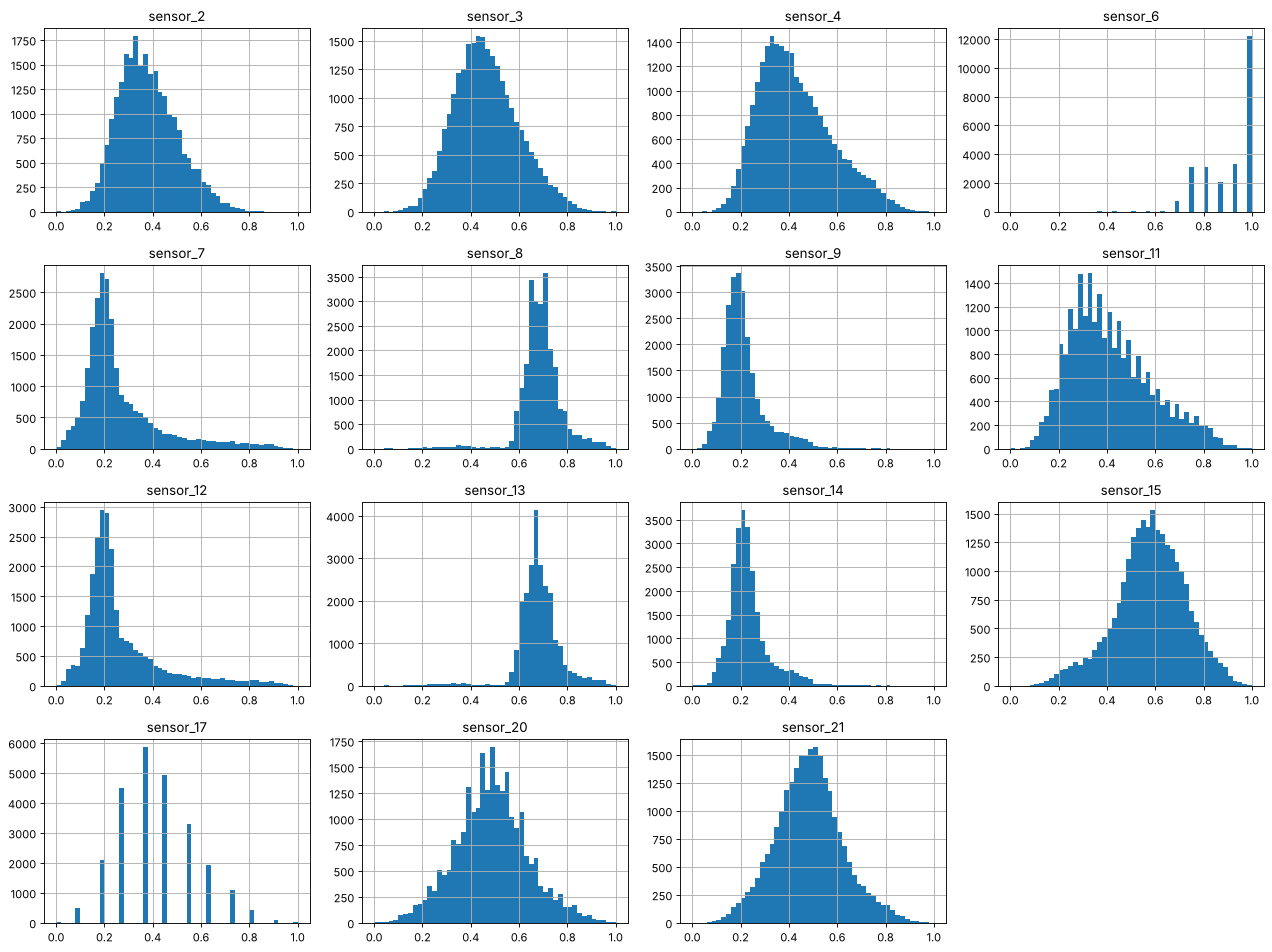

In [31]:
X_train_s.hist(bins=50, figsize=(16, 12))
plt.tight_layout()
plt.show()

## 6. Model 1: Lineer Regresyon

Tahmin etmek istediğimiz RUL **sürekli bir sayı** (örneğin 87 çevrim). Sayı tahmin eden modellere **regresyon** modeli denir. En basit regresyon modeli olan **Lineer Regresyon** ile başlıyoruz.

Modeli eğitmek için girdileri (`X`) ve tahmin edilecek değeri (`y`) ayırın:
- `X_train`: `df_train` içindeki `features` sütunları
- `y_train`: `df_train` içindeki `RUL` sütunu
- `X_test` ve `y_test`: aynısı, `df_test_last` için

In [32]:
X_train = df_train[features]
y_train = df_train["RUL"]

X_test = df_test_last[features]
y_test = df_test_last["RUL"]

print(X_train.shape, X_test.shape)

(24720, 15) (100, 15)


Bir `LinearRegression` modeli oluşturun, `X_train` ve `y_train` ile eğitin (`fit`), ardından `X_test` için tahmin yapın (`predict`) ve tahminleri `y_pred_lr` içine kaydedin.

In [33]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

Aşağıdaki kodu çalıştırarak ilk 10 test motoru için gerçek ve tahmin edilen değerleri yan yana görün.

In [34]:
comparison = pd.DataFrame({"Gerçek RUL": y_test, "Tahmin": y_pred_lr.round(0)})
comparison.head(10)

,Gerçek RUL,Tahmin
0,44,85.0
1,51,106.0
2,27,36.0
3,120,157.0
4,101,212.0
5,99,141.0
6,71,98.0
7,55,94.0
8,55,99.0
9,66,139.0


Şimdi modelin ne kadar iyi olduğunu ölçelim. İki metrik kullanacağız:
- **MAE (Ortalama Mutlak Hata):** Tahminlerimiz ortalamada kaç çevrim yanılıyor?
- **RMSE (Kök Ortalama Kare Hata):** Hataların karesini alıp ortalar, sonra karekök alır. Büyük hataları daha çok cezalandırır.

İkisi de **ne kadar küçükse o kadar iyi**. RMSE'yi `np.sqrt(mean_squared_error(...))`, MAE'yi `mean_absolute_error(...)` ile hesaplayın ve `rmse_lr`, `mae_lr` değişkenlerine kaydedin.

In [35]:
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("RMSE:", round(rmse_lr, 2))
print("MAE:", round(mae_lr, 2))

RMSE: 57.32
MAE: 47.28


Bu sonucu nasıl yorumlarsınız? Bir uçak bakım mühendisi için yeterli mi?

> **Örnek cevap:** MAE değeri, modelin bir motorun kalan ömrünü ortalamada kaç çevrim yanlış tahmin ettiğini gösteriyor. Motorların ömrü 130-360 çevrim arasında olduğu düşünülürse bu hata oldukça büyük. Bakım planlamasında güvenle kullanmak için hatayı azaltmamız gerekiyor.

## 7. İyileştirme: RUL'u 125'te sınırlama

Bir sorun var: Motor ilk çevrimlerde **tamamen sağlıklı**. Sensörler "bu motorun 300 çevrim mi yoksa 200 çevrim mi ömrü kaldı" farkını gösteremez; çünkü ikisinde de motor sağlıklı ve sensörler aynı.

Ama biz modelden, 1. çevrimdeki bir motor için RUL=300 tahmin etmesini istiyoruz. Bu, modelin öğrenmesi imkânsız bir şey!

**Çözüm:** RUL değerini 125'te sınırlayalım (clipping). "125'ten fazla ömrü kalan motor = sağlıklı motor" diyoruz. Bu yöntem bu veri setiyle yapılan bilimsel çalışmalarda çok yaygın kullanılır.

`df_train` tablosuna `RUL_clip` adında yeni bir sütun ekleyin: RUL değeri 125'ten büyükse 125 olsun, değilse aynı kalsın.

<details>
    <summary> İpucu 💡 </summary>

`.clip(upper=125)` 125'ten büyük değerleri 125'e eşitler.

</details>

In [36]:
df_train["RUL_clip"] = df_train["RUL"].clip(upper=125)
df_train[["unit", "cycle", "RUL", "RUL_clip"]].head()

,unit,cycle,RUL,RUL_clip
0,1,1,258,125
1,1,2,257,125
2,1,3,256,125
3,1,4,255,125
4,1,5,254,125


Aşağıdaki kodu çalıştırarak 1 numaralı motor için sınırlanmış ve sınırlanmamış RUL'u karşılaştırın.

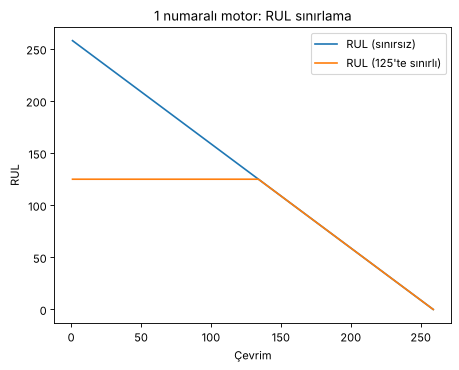

In [37]:
engine_1 = df_train[df_train["unit"] == 1]

plt.plot(engine_1["cycle"], engine_1["RUL"], label="RUL (sınırsız)")
plt.plot(engine_1["cycle"], engine_1["RUL_clip"], label="RUL (125'te sınırlı)")
plt.xlabel("Çevrim")
plt.ylabel("RUL")
plt.legend()
plt.title("1 numaralı motor: RUL sınırlama")
plt.show()

Modelimiz artık en fazla 125 tahmin etmeyi öğrenecek. Adil bir karşılaştırma için test verisindeki gerçek RUL değerlerini de 125'te sınırlamalıyız.

`y_train_clip` ve `y_test_clip` değişkenlerini oluşturun.

In [38]:
y_train_clip = df_train["RUL_clip"]
y_test_clip = df_test_last["RUL"].clip(upper=125)

Yeni bir Lineer Regresyon modelini `X_train` ve `y_train_clip` ile eğitin. Tahminleri `y_pred_lr_clip` içine kaydedin, ardından `y_test_clip` ile RMSE ve MAE hesaplayın (`rmse_lr_clip`, `mae_lr_clip`).

In [39]:
lr_model_clip = LinearRegression()
lr_model_clip.fit(X_train, y_train_clip)
y_pred_lr_clip = lr_model_clip.predict(X_test)

rmse_lr_clip = np.sqrt(mean_squared_error(y_test_clip, y_pred_lr_clip))
mae_lr_clip = mean_absolute_error(y_test_clip, y_pred_lr_clip)

print("RMSE:", round(rmse_lr_clip, 2))
print("MAE:", round(mae_lr_clip, 2))

RMSE: 20.48
MAE: 16.78


RMSE nasıl değişti? Sizce neden?

> **Örnek cevap:** RMSE belirgin şekilde düştü. Model artık "sensörlerden anlaşılamayan" yüksek RUL değerlerini tahmin etmeye çalışmıyor; sağlıklı motorları 125 olarak kabul ediyor ve asıl önemli bölgeye, yani arızaya yaklaşan motorlara odaklanıyor.

## 8. Model 2: Random Forest

Lineer Regresyon, sensörler ile RUL arasında **düz bir çizgi** gibi bir ilişki varsayar. Gerçekte ilişki daha karmaşık olabilir: motor uzun süre sağlıklı kalır, sonra hızla bozulur.

**Random Forest**, birçok **karar ağacının** tahminlerinin ortalamasını alan bir modeldir. Her ağaç "sensor_11 > 47.5 mi? Evet ise..." gibi sorularla tahmin yapar. Bu sayede doğrusal olmayan ilişkileri de yakalayabilir.

Bir `RandomForestRegressor` modeli oluşturun:
- `n_estimators=100` → 100 ağaç
- `max_depth=10` → her ağaç en fazla 10 soru derinliğinde (aşırı ezberlemeyi önler)
- `random_state=42` → her çalıştırmada aynı sonuç
- `n_jobs=-1` → bilgisayarın tüm işlemci çekirdeklerini kullan (daha hızlı)

Modeli `X_train` ve `y_train_clip` ile eğitin, `X_test` için tahmin yapın (`y_pred_rf`), RMSE ve MAE hesaplayın (`rmse_rf`, `mae_rf`).

In [40]:
rf_model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train_clip)
y_pred_rf = rf_model.predict(X_test)

rmse_rf = np.sqrt(mean_squared_error(y_test_clip, y_pred_rf))
mae_rf = mean_absolute_error(y_test_clip, y_pred_rf)

print("RMSE:", round(rmse_rf, 2))
print("MAE:", round(mae_rf, 2))

RMSE: 20.18
MAE: 14.86


### Ezberleme kontrolü

Bir model eğitim verisini **ezberleyip** test verisinde kötü çıkabilir. Bunu anlamak için modelin **eğitim** verisindeki hatasına da bakarız.

`X_train` için tahmin yapın (`y_pred_rf_train`), `y_train_clip` ile RMSE hesaplayıp `rmse_rf_train` içine kaydedin. Sonra eğitim ve test RMSE'sini yan yana yazdırın.

In [41]:
y_pred_rf_train = rf_model.predict(X_train)
rmse_rf_train = np.sqrt(mean_squared_error(y_train_clip, y_pred_rf_train))

print("Train RMSE:", round(rmse_rf_train, 2))
print("Test RMSE:", round(rmse_rf, 2))

Train RMSE: 12.85
Test RMSE: 20.18


Eğitim ve test hatası arasında büyük bir fark var mı? Bu ne anlama gelir?

> **Örnek cevap:** Train RMSE 12.85, test RMSE 20.18. Bu veri setinde fark diğerlerinden büyük: hafif bir ezberleme işareti olabilir. Model eğitim verisinde daha iyi, görmediği motorlarda daha kötü. Yine de fark aşırı değil. Eğitim hatası çok düşük, test hatası yüksek olsaydı bu ezberleme (overfitting) işareti olurdu. Not: eğitim hatası tüm satırlar üzerinden, test hatası her motorun yalnızca son satırı üzerinden hesaplandığı için bu karşılaştırma yaklaşık bir kontroldür.

Random Forest bize hangi sensörün tahmin için ne kadar önemli olduğunu da söyler. Aşağıdaki kodu çalıştırın.

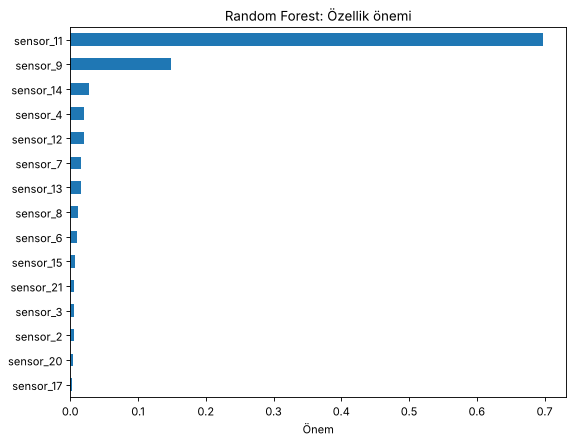

In [42]:
importance = pd.Series(rf_model.feature_importances_, index=features)
importance.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest: Özellik önemi")
plt.xlabel("Önem")
plt.show()

Aşağıdaki kodu çalıştırarak en önemli 3 özelliği ve ne ölçtüklerini görün.

In [43]:
top3 = importance.sort_values(ascending=False).head(3)

for s in top3.index:
    print(s, "| önem:", round(top3[s], 2), "|", Sensor_dictionary.get(s, "çalışma ayarı"))

sensor_11 | önem: 0.7 | (HPC outlet Static pressure) (psia)
sensor_9 | önem: 0.15 | (Physical core speed) (rpm)
sensor_14 | önem: 0.03 | (Corrected core speed) (rpm)


En önemli 3 sensör hangisi? 4. bölümdeki korelasyon sonuçlarıyla uyumlu mu?

> **Örnek cevap:** Grafiğin en üstündeki sensör açık ara `sensor_11` (HPC çıkış statik basıncı). Bu, 4. bölümde RUL ile en güçlü korelasyonu gösteren sensörle aynı; yani iki farklı yöntem (korelasyon ve Random Forest) aynı sensörü işaret ediyor. Diğer önemli sensörler korelasyon listesinden biraz farklı olabilir, çünkü Random Forest doğrusal olmayan ilişkileri de yakalar.

## 9. Sonuçları karşılaştırma

Şimdi üçüncü bir metrik ekleyelim: **R² (belirlilik katsayısı)**. Modelin RUL'daki değişimin ne kadarını açıkladığını gösterir:
- **1'e yakın** → model çok iyi
- **0 civarı** → model, "herkese ortalamayı söyle" yönteminden farksız
- **Negatif** → model ortalamayı söylemekten bile kötü

RMSE ve MAE hatayı **çevrim cinsinden** verir, R² ise **genel uyumu** gösterir; ikisi birbirini tamamlar. `r2_score(gerçek, tahmin)` ile üç modelin R² değerlerini hesaplayın (`r2_lr`, `r2_lr_clip`, `r2_rf`). RMSE ve MAE'de olduğu gibi, sınırlanmış RUL ile eğitilen modeller `y_test_clip` ile karşılaştırılır.

In [44]:
r2_lr = r2_score(y_test, y_pred_lr)
r2_lr_clip = r2_score(y_test_clip, y_pred_lr_clip)
r2_rf = r2_score(y_test_clip, y_pred_rf)

print("Lineer Regresyon (sınırsız RUL) R2:", round(r2_lr, 3))
print("Lineer Regresyon (RUL ≤ 125) R2:", round(r2_lr_clip, 3))
print("Random Forest (RUL ≤ 125) R2:", round(r2_rf, 3))

Lineer Regresyon (sınırsız RUL) R2: -0.917
Lineer Regresyon (RUL ≤ 125) R2: 0.727
Random Forest (RUL ≤ 125) R2: 0.735


Üç modelin RMSE, MAE ve R² değerlerini bir tabloda toplayın.

In [45]:
results = pd.DataFrame({
    "Model": ["Lineer Regresyon (sınırsız RUL)", "Lineer Regresyon (RUL ≤ 125)", "Random Forest (RUL ≤ 125)"],
    "RMSE": [rmse_lr, rmse_lr_clip, rmse_rf],
    "MAE": [mae_lr, mae_lr_clip, mae_rf],
    "R2": [r2_lr, r2_lr_clip, r2_rf]
})
results.round(2)

,Model,RMSE,MAE,R2
0,Lineer Regresyon (sınırsız RUL),57.32,47.28,-0.92
1,Lineer Regresyon (RUL ≤ 125),20.48,16.78,0.73
2,Random Forest (RUL ≤ 125),20.18,14.86,0.73


Aşağıdaki kodu çalıştırarak tahminleri gerçek değerlerle karşılaştırın. Her test motoru için **mavi çubuk gerçek RUL**, üstüne çizilen **ince kırmızı çubuk tahmin edilen RUL**'dur.

- Kırmızı çubuk mavinin **üstüne taşıyorsa**: model motorun ömrünü **olduğundan uzun** tahmin etmiş (bakım açısından tehlikeli yön).
- Kırmızı çubuk mavinin **içinde kalıyorsa**: model ömrü **olduğundan kısa** tahmin etmiş (temkinli hata).
- Çubuklar ne kadar yakınsa tahmin o kadar iyi. RUL 125'te sınırlandığı için hiçbir çubuk 125'i geçmez.

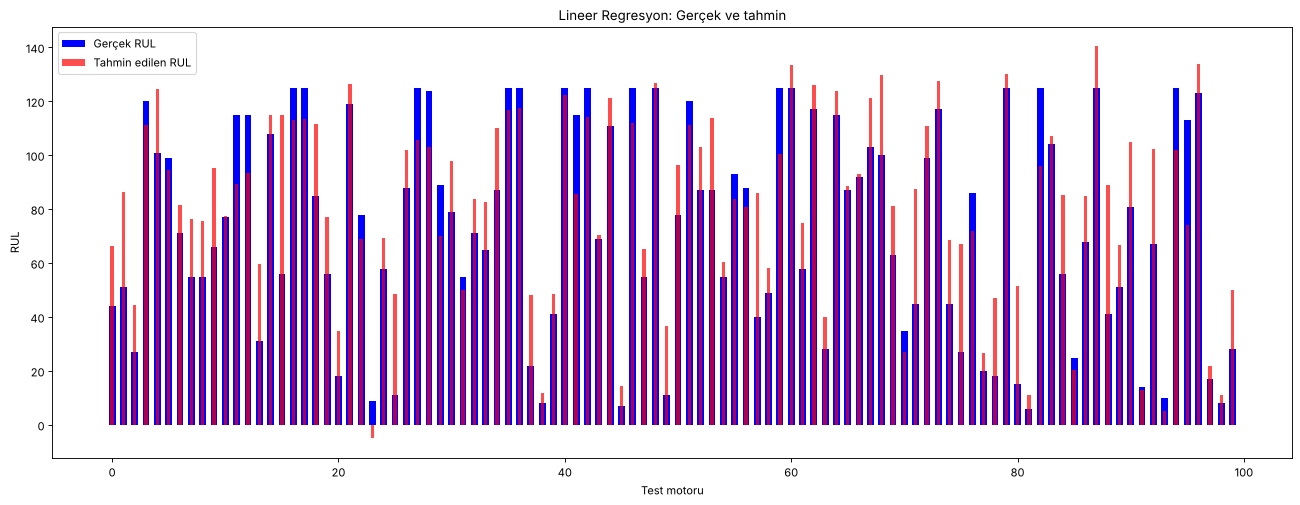

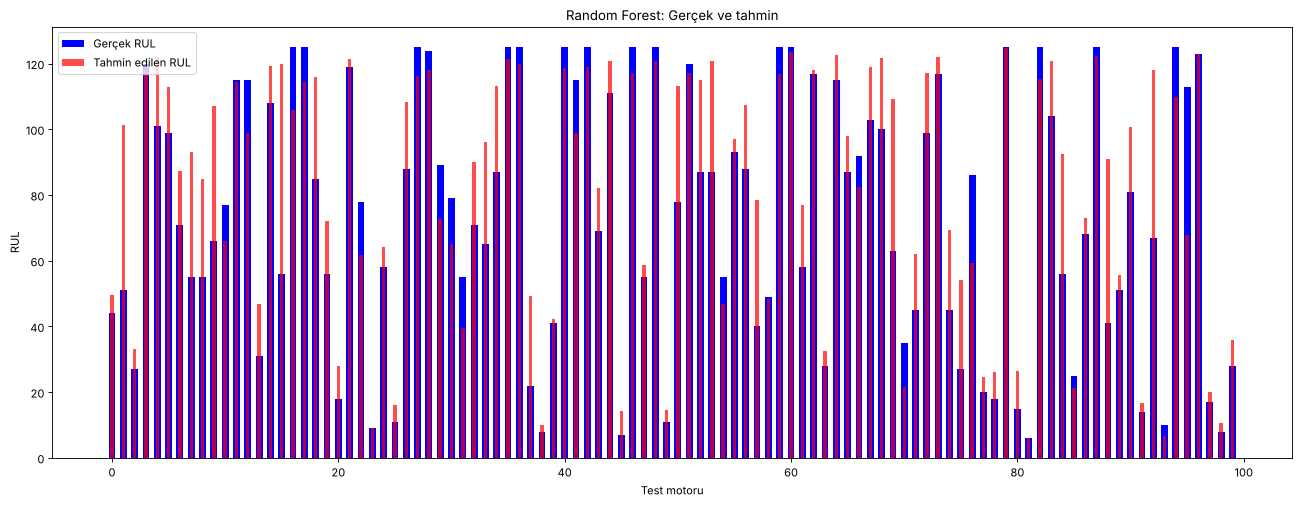

In [46]:
def plot_predActual(y_true, y_pred, title):
    x = np.arange(len(y_true))
    plt.figure(figsize=(20, 7))
    plt.bar(x, y_true, width=0.6, color="blue", label="Gerçek RUL")
    plt.bar(x, y_pred, width=0.3, color="red", alpha=0.7, label="Tahmin edilen RUL")
    plt.xlabel("Test motoru")
    plt.ylabel("RUL")
    plt.title(title)
    plt.legend()
    plt.show()

plot_predActual(y_test_clip, y_pred_lr_clip, "Lineer Regresyon: Gerçek ve tahmin")
plot_predActual(y_test_clip, y_pred_rf, "Random Forest: Gerçek ve tahmin")

### Tahmin yönü: ömrü fazla mı, az mı tahmin ediyoruz?

Çubuk grafikte kırmızı çubuğun maviyi aşması, modelin ömrü **olduğundan uzun** tahmin etmesidir; bu bakım için **tehlikeli yöndür**. Bunu sayıyla görelim.

Random Forest için ömrü olduğundan uzun tahmin edilen motor sayısını `over` içine, kısa tahmin edilenleri `under` içine kaydedin.

<details>
    <summary> İpucu 💡 </summary>

`(y_pred_rf > y_test_clip).sum()` tahminin gerçekten büyük olduğu motorları sayar.

</details>

In [47]:
over = int((y_pred_rf > y_test_clip).sum())
under = len(y_test_clip) - over

print("Ömrü olduğundan UZUN tahmin edilen motor:", over, "/", len(y_test_clip))
print("Ömrü olduğundan KISA tahmin edilen motor:", under, "/", len(y_test_clip))

Ömrü olduğundan UZUN tahmin edilen motor: 65 / 100
Ömrü olduğundan KISA tahmin edilen motor: 35 / 100


Model sistematik olarak iyimser mi (ömrü fazla tahmin ediyor) yoksa dengeli mi? Bakım açısından bu neden önemli?

> **Örnek cevap:** 100 test motorunun 65 tanesinde ömür olduğundan uzun, 35 tanesinde kısa tahmin edilmiş. Fazla tahmin oranı %65: model belirgin şekilde **iyimser** eğilimde. Bakım açısından bu, arızaya yakın bir motoru "daha dayanır" sanma riski demektir; raporda mutlaka belirtilmeli. Fazla tahmin, kalan ömrü olduğundan uzun sanmak anlamına geldiği için bakım ekibi açısından, az tahminden (gereksiz erken bakım) daha tehlikelidir.

### NASA skoru: geç tahmin daha pahalı

RMSE, fazla ve az tahmini **aynı ağırlıkta** cezalandırır. NASA'nın bu yarışma için tanımladığı **skor** ise ömrü **fazla tahmin etmeyi (geç bakım) daha ağır** cezalandırır. Hata `d = tahmin − gerçek` olsun:
- `d < 0` (az tahmin): ceza = `e^(−d/13) − 1`
- `d ≥ 0` (fazla tahmin): ceza = `e^(d/10) − 1`

Örneğin 10 çevrim fazla tahmin yaklaşık 1.72, 10 çevrim az tahmin yaklaşık 1.16 puan ceza getirir. Skor **ne kadar küçükse o kadar iyidir**.

`nasa_score(y_true, y_pred)` adında bir fonksiyon yazın (her motorun cezasını toplasın). Sonra Lineer Regresyon (RUL ≤ 125) ve Random Forest için skoru hesaplayıp `score_lr_clip` ve `score_rf` içine kaydedin.

<details>
    <summary> İpucu 💡 </summary>

`d = np.asarray(y_pred) - np.asarray(y_true)` ile hatayı bulun. `np.where(d < 0, ceza_az, ceza_fazla)` her motor için doğru formülü seçer, `.sum()` toplar.

</details>

In [48]:
def nasa_score(y_true, y_pred):
    d = np.asarray(y_pred) - np.asarray(y_true)
    ceza = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
    return ceza.sum()

score_lr_clip = nasa_score(y_test_clip, y_pred_lr_clip)
score_rf = nasa_score(y_test_clip, y_pred_rf)

print("NASA skoru Lineer Regresyon (RUL ≤ 125):", round(score_lr_clip))
print("NASA skoru Random Forest (RUL ≤ 125):", round(score_rf))
print("Motor başına ortalama ceza (Random Forest):", round(score_rf / len(y_test_clip), 1))

NASA skoru Lineer Regresyon (RUL ≤ 125): 1242
NASA skoru Random Forest (RUL ≤ 125): 1710
Motor başına ortalama ceza (Random Forest): 17.1


> **Not:** Resmi NASA skoru RUL sınırlanmadan hesaplanır. Biz sınırlı RUL kullandığımız için sayılarımız literatürdeki skorlarla **birebir kıyaslanamaz**; burada yalnızca kendi modellerimizi birbirleriyle karşılaştırıyoruz.

NASA skoruna göre hangi model daha iyi? Sıralama RMSE ile aynı mı? Bu skor güvenlik açısından neden anlamlı?

> **Örnek cevap:** Lineer Regresyon (RUL ≤ 125) için skor 1242, Random Forest için 1710; daha küçük skor daha iyi olduğundan **Lineer Regresyon** öne çıkıyor (aradaki oran yaklaşık 1.4 kat). Bu, RMSE sıralamasından **farklı**: RMSE'ye göre Random Forest daha iyiydi, NASA skoruna göre Lineer Regresyon. Nedeni: Random Forest'te ömrü 20 çevrimden fazla fazla tahmin ettiği motor sayısı daha az, ama birkaç motorda fazla tahmin hatası Lineer Regresyondakinden daha büyük; ceza üstel arttığı için bu birkaç motor skoru şişiriyor. Yani tek bir ölçüte bakmak yanıltıcı olabilir. NASA skoru geç tahmini (ömrü fazla sanmayı) daha çok cezalandırdığı için bakım güvenliğini yansıtır: büyük bir fazla tahmin üstel olarak büyüyen ceza getirir. Bu yüzden RMSE ile birlikte raporlanması iyi olur.

Hangi model en iyi? Raporunuz için 2-3 cümlelik bir sonuç yazın.

> **Örnek cevap:** Random Forest (RUL ≤ 125): RMSE 20.18, MAE 14.86, R² 0.73. Lineer Regresyon (RUL ≤ 125): RMSE 20.48, MAE 16.78, R² 0.73. RMSE ve R² neredeyse aynı; fark en çok MAE'de: Random Forest ortalamada yaklaşık 1.9 çevrim daha az yanılıyor. Bu yüzden Random Forest'i seçtik, ama bu veri setinde avantajı küçük. Asıl büyük fark RUL sınırlamasından geldi: sınırsız RUL ile eğitilen Lineer Regresyonun R² değeri -0.92, yani "herkese ortalamayı söyle" yönteminden bile kötü. **Neden Random Forest'i seçtik?** Lineer Regresyon, sensörler ile RUL arasında düz bir çizgi ilişkisi varsayar; motor yıpranması ise doğrusal değildir (başta yavaş, sonda hızlı ilerler). Random Forest bu eğri ilişkileri yakalayabilir ve sonuç tablosunda hata değerleri daha düşük çıktı. Çubuk grafikte bazı motorlarda tahminlerin gerçek değerden uzak olduğu görülüyor.

## 10. Bonus: Sınıflandırma — "Motor 30 çevrim içinde arızalanacak mı?"

Bakım ekibi için bazen kesin sayıdan çok basit bir soru önemlidir: **"Bu motoru şimdi bakıma almalı mıyım?"**

Soruyu **evet/hayır** şekline çevirelim:
- RUL ≤ 30 ise → **1** (arızaya yakın, bakıma al)
- RUL > 30 ise → **0** (sağlam)

Cevap bir sayı değil bir **sınıf** olduğu için bu bir **sınıflandırma** problemi.

`df_train` ve `df_test_last` tablolarına `fail_30` adında bu etiketi içeren bir sütun ekleyin.

<details>
    <summary> İpucu 💡 </summary>

`(df_train["RUL"] <= 30)` True/False döndürür. `.astype(int)` ile True → 1, False → 0 olur.

</details>

In [49]:
df_train["fail_30"] = (df_train["RUL"] <= 30).astype(int)
df_test_last["fail_30"] = (df_test_last["RUL"] <= 30).astype(int)

Train verisinde sınıfların oranı nedir? `.value_counts()` fonksiyonunu `normalize=True` argümanıyla kullanın.

In [50]:
df_train["fail_30"].value_counts(normalize=True)

fail_30
0    0.874595
1    0.125405
Name: proportion, dtype: float64

Sınıflar dengeli mi? Bu neden önemli olabilir?

> **Örnek cevap:** Dengeli değil: train satırlarının yaklaşık %87.5'i "sağlam" (0), sadece %12.5'i "arızaya yakın" (1). Test motorlarında da benzer: 20 motor arızaya yakın, geri kalanı sağlam. Bu yüzden her motora "sağlam" diyen tembel bir model bile test verisinde yaklaşık %80 doğruluk alır. Sadece doğruluğa (accuracy) bakmak yanıltıcı olabilir; başka metriklere de bakmamız gerekiyor.

**Lojistik Regresyon** ile sınıflandırma yapacağız. Bu model, sensör değerlerinin **farklı ölçeklerde** olmasından etkilenir (bir sensör 0-1 arası, diğeri 9000 civarında). Bu yüzden önce tüm özellikleri aynı ölçeğe getiriyoruz (**StandardScaler**: her sütunun ortalaması 0, std'si 1 olur).

Aşağıdaki kodu çalıştırın. Dikkat: `fit_transform` sadece train'de kullanılır; test verisine train'den öğrenilen ölçek `transform` ile uygulanır.

In [51]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

`y_train_class` ve `y_test_class` değişkenlerini oluşturun. Bir `LogisticRegression(max_iter=1000)` modeli eğitin ve test tahminlerini `y_pred_class` içine kaydedin.

In [52]:
y_train_class = df_train["fail_30"]
y_test_class = df_test_last["fail_30"]

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train_class)
y_pred_class = log_model.predict(X_test_scaled)

### Confusion Matrix (Karışıklık Matrisi)

Confusion matrix, modelin doğru ve yanlış tahminlerini 4 kutuda gösterir:

|  | Tahmin: 0 (sağlam) | Tahmin: 1 (arızaya yakın) |
|---|---|---|
| **Gerçek: 0 (sağlam)** | **TN** (True Negative) — doğru, sağlam dedi | **FP** (False Positive) — yanlış alarm |
| **Gerçek: 1 (arızaya yakın)** | **FN** (False Negative) — arızayı kaçırdı! | **TP** (True Positive) — doğru, arızayı yakaladı |

`confusion_matrix(y_test_class, y_pred_class)` ile matrisi hesaplayıp `cm` içine kaydedin ve yazdırın.

In [53]:
cm = confusion_matrix(y_test_class, y_pred_class)
print(cm)

[[79  1]
 [ 5 15]]


Aşağıdaki kodu çalıştırarak matrisi görselleştirin.

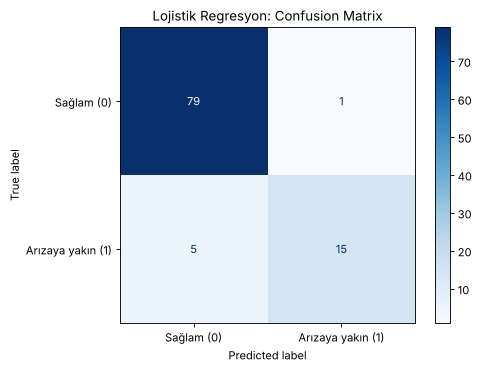

In [54]:
ConfusionMatrixDisplay(cm, display_labels=["Sağlam (0)", "Arızaya yakın (1)"]).plot(cmap="Blues")
plt.title("Lojistik Regresyon: Confusion Matrix")
plt.show()

Matristeki 4 değeri ayrı değişkenlere alın. `cm.ravel()` matrisi düz bir listeye çevirir: sırası **TN, FP, FN, TP**.

In [55]:
tn, fp, fn, tp = cm.ravel()
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)
print("TP:", tp)

TN: 79
FP: 1
FN: 5
TP: 15


Şimdi üç metrik hesaplayın:
- **Accuracy (Doğruluk)** = (TP + TN) / toplam → Tüm tahminlerin yüzde kaçı doğru?
- **Precision (Kesinlik)** = TP / (TP + FP) → "Arızaya yakın" dediğimiz motorların yüzde kaçı gerçekten arızaya yakın?
- **Recall (Duyarlılık)** = TP / (TP + FN) → Gerçekten arızaya yakın olan motorların yüzde kaçını yakaladık?

`accuracy_score`, `precision_score` ve `recall_score` fonksiyonlarını kullanın.

In [56]:
print("Accuracy:", round(accuracy_score(y_test_class, y_pred_class), 2))
print("Precision:", round(precision_score(y_test_class, y_pred_class), 2))
print("Recall:", round(recall_score(y_test_class, y_pred_class), 2))

Accuracy: 0.94
Precision: 0.94
Recall: 0.75


Uçak motorları için hangisi daha tehlikeli: **FP** mi, **FN** mi? Bu durumda hangi metrik daha önemli?

> **Örnek cevap:** **FN daha tehlikeli.** FP, sağlam bir motoru gereksiz yere bakıma almak demek: masraflı ama güvenli. FN ise arızaya yakın bir motoru "sağlam" sanıp uçurmak demek: ciddi bir güvenlik riski. Bu yüzden FN'yi azaltmayı hedefleyen **Recall** metriği bizim için daha önemli. Bizim modelde precision 0.94, recall 0.75: model arızaya yakın 20 motordan 5 tanesini kaçırıyor (FN = 5), buna karşılık sadece 1 yanlış alarm veriyor (FP = 1). Yani model temkinsiz: "arızaya yakın" demekte fazla çekingen. Bu, gelecekte geliştirilebilecek bir nokta (örneğin karar eşiğini düşürerek recall artırılabilir).

## 11. KPI'lar: sayıdan öneriye

Bir yönetici RMSE değerini sormaz; şunu sorar: **"Motorların kaçında tahmine güvenebilirim ve bakım uyarısı ne kadar işe yarıyor?"** Bu yüzden RMSE'yi iş diline çeviren KPI'lar hesaplayalım. Aşağıdaki kodu çalıştırın.

In [57]:
hata = y_pred_rf - y_test_clip

print("Ortalama hata (MAE):", round(mae_rf, 1), "çevrim")
print("±10 çevrim içinde tahmin edilen motor: %", round((hata.abs() <= 10).mean() * 100))
print("±20 çevrim içinde tahmin edilen motor: %", round((hata.abs() <= 20).mean() * 100))

Ortalama hata (MAE): 14.9 çevrim
±10 çevrim içinde tahmin edilen motor: % 49
±20 çevrim içinde tahmin edilen motor: % 76


Şimdi **bakım uyarısı** kuralını deneyelim: Random Forest'in tahmini `esik` çevrimin altına düşerse alarm verilsin. Gerçekten arızaya yakın motorlar (`y_test_clip <= 30`) için:
- **Yakalanan arıza:** alarm verildi ve gerçekten arızaya yakın
- **Kaçırılan arıza:** alarm yok ama gerçekten arızaya yakın
- **Yanlış alarm:** alarm verildi ama motor aslında arızaya yakın değil

Eşiği 30, 40 ve 50 yaparak her seferinde bu üç sayıyı bulun ve `alarm_tablosu` adında bir tabloda toplayın.

<details>
    <summary> İpucu 💡 </summary>

`alarm = y_pred_rf <= esik` ve `gercek_yakin = y_test_clip <= 30` yazın. `alarm & gercek_yakin` yakalananı, `~alarm & gercek_yakin` kaçırılanı, `alarm & ~gercek_yakin` yanlış alarmı seçer. `.sum()` ile sayın.

</details>

In [58]:
gercek_yakin = y_test_clip <= 30

satirlar = []
for esik in [30, 40, 50]:
    alarm = y_pred_rf <= esik
    yakalanan = int((alarm & gercek_yakin).sum())
    kacirilan = int((~alarm & gercek_yakin).sum())
    yanlis_alarm = int((alarm & ~gercek_yakin).sum())
    satirlar.append([esik, yakalanan, kacirilan, yanlis_alarm])

alarm_tablosu = pd.DataFrame(satirlar, columns=["Alarm eşiği", "Yakalanan arıza", "Kaçırılan arıza", "Yanlış alarm"])
alarm_tablosu["Yakalama oranı (%)"] = (alarm_tablosu["Yakalanan arıza"] / gercek_yakin.sum() * 100).round().astype(int)
alarm_tablosu

,Alarm eşiği,Yakalanan arıza,Kaçırılan arıza,Yanlış alarm,Yakalama oranı (%)
0,30,15,5,1,75
1,40,18,2,2,90
2,50,19,1,7,95


Eşiği 30'dan 50'ye çıkarınca yakalanan arıza sayısı ve yanlış alarm nasıl değişti? Bakım ekibine hangi eşiği önerirsiniz ve neden?

> **Örnek cevap:** Gerçekten arızaya yakın 20 motor var. Eşik 30 iken 15 tanesi yakalandı, 5 tanesi kaçırıldı, 1 yanlış alarm verildi. Eşik 50'ye çıkınca yakalanan 19, kaçırılan 1, yanlış alarm 7 oldu. Yani eşiği yükseltmek kaçırılan arızayı azaltıyor (ya da en azından artırmıyor) ama yanlış alarmı artırıyor: bu bir **denge** meselesi. Uçak güvenliğinde kaçırılan arıza yanlış alarmdan çok daha pahalı olduğu için 30 yerine daha yüksek bir eşik (örneğin 40) ile bir **güvenlik payı** bırakmak mantıklı; doğru eşik, yanlış alarmın maliyetine bakım ekibiyle birlikte karar verilmeli. Ayrıca model ortalamada 14.9 çevrim şaşıyor ve motorların %49'i ±10, %76'i ±20 çevrim içinde tahmin edildi; tek bir tahmine kesin gözle bakmamalıyız.

## Sonuç

Bu çalışmada neler öğrendiniz? Bitirme raporunuz için en önemli 3 bulguyu yazın.

> **Örnek cevap:** 1) Hiç değişmeyen sensörler modele bilgi vermez, bu yüzden çıkarılmalıdır. 2) RUL'u 125'te sınırlamak, sağlıklı dönemdeki "tahmin edilemez" bilgiyi ortadan kaldırarak hatayı belirgin şekilde azalttı. 3) Random Forest, doğrusal olmayan ilişkileri yakalayabildiği için Lineer Regresyondan daha iyi sonuç verdi (bu veri setinde fark küçük, en çok MAE'de). 4) Tek metriğe bakmak yetmez: RMSE, MAE, R² ve geç tahmini daha çok cezalandıran NASA skoru birlikte değerlendirilmeli. Bu veri setinde NASA skoruna göre Lineer Regresyon daha iyi çıktı (Random Forest'in birkaç büyük fazla tahmini skoru şişiriyor), bu yüzden "Random Forest her ölçüte göre daha iyi" demek doğru olmaz. 5) Bakım uyarısında eşiği yükseltmek kaçırılan arızayı azaltır ama yanlış alarmı artırır; güvenlik için eşik bir güvenlik payıyla seçilmeli.